In [1]:
'''Derive actionable business insights from admission model outputs, such as identifying top-performing applicant profiles and understanding key factors influencing acceptance rates.'''

'Derive actionable business insights from admission model outputs, such as identifying top-performing applicant profiles and understanding key factors influencing acceptance rates.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error


In [3]:
# load and preprocess dataset
df = pd.read_csv('Adm.csv')
df.columns = df.columns.str.strip()
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'
print('dataset rows and columns:', df.shape)
df.head()


dataset rows and columns: (1000, 12)
Out[1]: 
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West
3           4        322  ...                        Jamia Millia Islamia   North
4           5        314  ...                        Jamia Millia Islamia   North

[5 rows x 12 columns]


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# train admission prediction model
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

df['Predicted_Chance'] = model.predict(X)
print('test r2 score:', round(r2_score(y_test, model.predict(X_test)), 4))
print('test mae:', round(mean_absolute_error(y_test, model.predict(X_test)), 4))


test r2 score: 0.9084
test mae: 0.0234


In [5]:
# analyze key factors influencing admission
importance_df = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values(by='importance', ascending=True)

print('key factors influencing acceptance rate:')
importance_df.sort_values(by='importance', ascending=False)


key factors influencing acceptance rate:
Out[1]: 
             feature  importance
5               CGPA    0.782794
0          GRE Score    0.080623
1        TOEFL Score    0.063816
4                LOR    0.035542
6           Research    0.016311
2  University Rating    0.010542
3                SOP    0.010372


,feature,importance
5,CGPA,0.782794
0,GRE Score,0.080623
1,TOEFL Score,0.063816
4,LOR,0.035542
6,Research,0.016311
2,University Rating,0.010542
3,SOP,0.010372


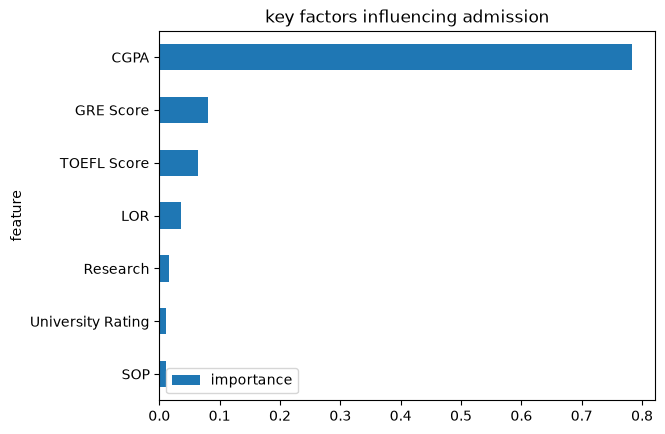

In [6]:
# plot key factors influencing admission
importance_df.plot(x='feature', y='importance', kind='barh', title='key factors influencing admission')
plt.show()


In [7]:
# identify and profile top performing applicants versus low performing applicants
df['Applicant_Profile'] = np.where(df['Predicted_Chance'] >= 0.80, 'Top Performing',
                          np.where(df['Predicted_Chance'] < 0.60, 'Low Performing', 'Average'))

profile_comparison = df.groupby('Applicant_Profile')[features + ['Predicted_Chance']].mean()
print('applicant profile averages:')
profile_comparison


applicant profile averages:
Out[1]: 
                    GRE Score  TOEFL Score  ...  Research  Predicted_Chance
Applicant_Profile                           ...                            
Average            314.910198   106.242009  ...  0.449011          0.702841
Low Performing     305.844961   100.062016  ...  0.271318          0.547471
Top Performing     325.303738   111.471963  ...  0.808411          0.863594

[3 rows x 8 columns]


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Predicted_Chance
Applicant_Profile,,,,,,,,
Average,314.910198,106.242009,2.908676,3.320091,3.339878,8.520807,0.449011,0.702841
Low Performing,305.844961,100.062016,2.341085,2.891473,2.772868,7.671783,0.271318,0.547471
Top Performing,325.303738,111.471963,3.747664,3.921495,3.993925,9.354953,0.808411,0.863594


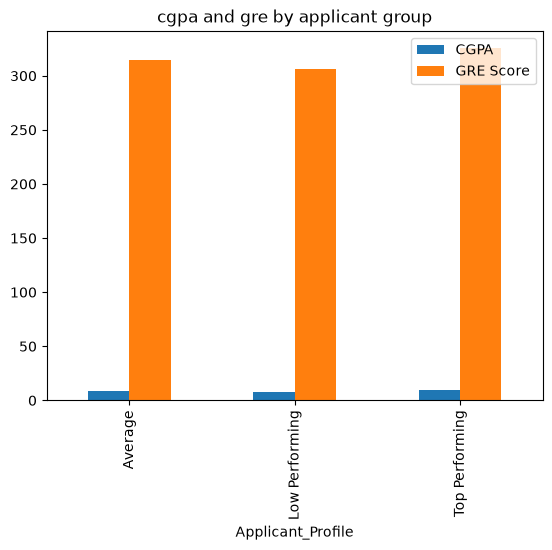

In [8]:
# plot profile comparison between applicant groups
profile_comparison[['CGPA', 'GRE Score']].plot(kind='bar', title='cgpa and gre by applicant group')
plt.show()


average admission chance by university rating:
University Rating
1    0.674118
2    0.672711
3    0.711935
4    0.757667
5    0.775619
Name: Predicted_Chance, dtype: float64


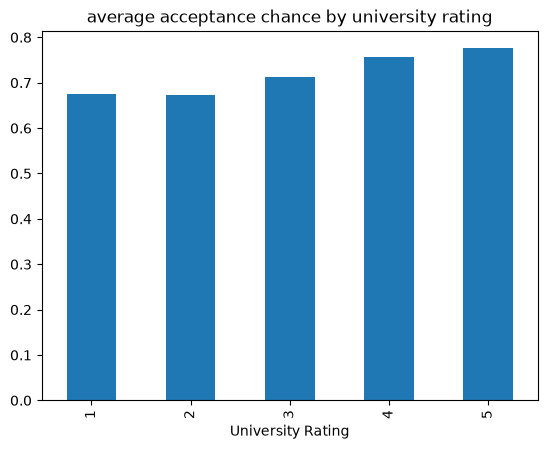

In [9]:
# analyze acceptance rate by university rating
rating_analysis = df.groupby('University Rating')['Predicted_Chance'].mean()
print('average admission chance by university rating:')
print(rating_analysis)
rating_analysis.plot(kind='bar', title='average acceptance chance by university rating')
plt.show()


average admission chance by region:
region
Central      0.725300
East         0.716884
North        0.720403
Northeast    0.724148
South        0.713167
West         0.718551
Name: Predicted_Chance, dtype: float64


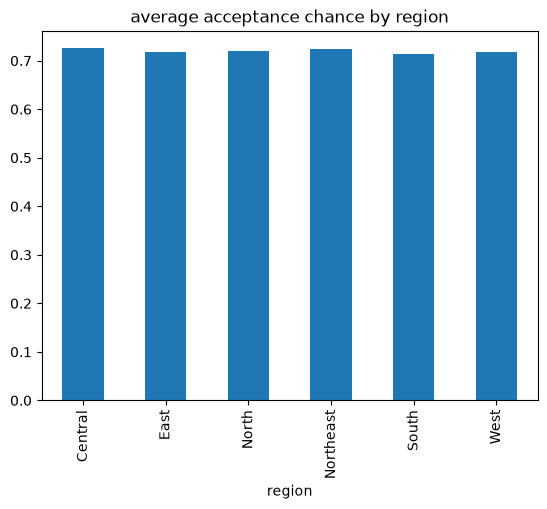

In [10]:
# analyze acceptance rate by geographic region
region_analysis = df.groupby('region')['Predicted_Chance'].mean()
print('average admission chance by region:')
print(region_analysis)
region_analysis.plot(kind='bar', title='average acceptance chance by region')
plt.show()


In [11]:
# summarize actionable business insights for decision makers
top_applicant = profile_comparison.loc['Top Performing']
low_applicant = profile_comparison.loc['Low Performing']

print('actionable business insights:')
print(f'1. top candidates maintain average cgpa of {top_applicant["CGPA"]:.2f} and gre of {top_applicant["GRE Score"]:.1f}.')
print(f'2. \'{importance_df.iloc[-1]["feature"]}\' is the strongest predictor of acceptance.')
print(f'3. research participation is {top_applicant["Research"]*100:.1f}% among top applicants vs {low_applicant["Research"]*100:.1f}% for low performing applicants.')
print(f'4. applicants to university rating 5 achieve highest mean chance ({rating_analysis.loc[5]:.2f}).')
print('5. university staff can prioritize fast-track evaluation for applicants with cgpa >= 8.8 and gre >= 320.')


actionable business insights:
1. top candidates maintain average cgpa of 9.35 and gre of 325.3.
2. 'CGPA' is the strongest predictor of acceptance.
3. research participation is 80.8% among top applicants vs 27.1% for low performing applicants.
4. applicants to university rating 5 achieve highest mean chance (0.78).
5. university staff can prioritize fast-track evaluation for applicants with cgpa >= 8.8 and gre >= 320.
